# Decoding finger velocity, and why not position

This notebook trains a small decoder to predict finger velocity from spike-band power, which is the regression the online system itself performed: the paper's decoder is "a temporally convolved feed-forward neural network [that] mapped spike-band power to finger velocities used to control virtual finger movements on screen."

Two things are worth being upfront about.

**The target is the online decoder's output, not an independent measurement.** T5 is tetraplegic, so nothing physical moves and nothing is recorded off a hand. `GraspSeries` is what the online network produced from these same features. So this is a measure of how much of the online decode is recoverable offline from the same 50 ms bins, not of how well intention can be read out in general. It is still the right thing to build a corpus example on, because it is the only continuous kinematic signal the dataset has.

**Position is the wrong target and the notebook shows it.** The obvious choice is to regress the finger positions directly. That fails, for the reason the online system already encodes: motor cortex carries movement intent, and position is the integral of it, so a 2 s neural window does not determine where the fingers currently are. We train both and compare.

In [1]:
import matplotlib.pyplot as plt
import neuralset as ns
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.willsey_2025 import utils
from neuralshed.datasets.willsey_2025.study import Willsey2025FingerDecoding
from neuralshed.extractors import BehavioralSeriesExtractor, NeuralFeatureExtractor

torch.manual_seed(0)

# 2 s windows on the source 20 Hz grid, stepped by 0.5 s so windows overlap.
FS = utils.FS
WINDOW_S = 2.0
STRIDE_S = 0.5
TRAIN_DAY = "t5.2023.03.23"
EPOCHS = 25

## Choosing blocks

Only the closed-loop blocks whose task cued all four degrees of freedom, so every dimension carries real targets. That is 36 of the 58 closed-loop blocks, spread over six recording days. 2023-03-23 is the training day because it is the longest single-day run in the release, eleven consecutive blocks on one decoder.

In [2]:
study = Willsey2025FingerDecoding(
    path=str(dataset_dir("willsey_2025") / "data"),
    query="block_kind == 'closed_loop' and task_dof == '4'",
)
events = study.run()

blocks = events[["session", "run", "post_implant_day"]].drop_duplicates()
print(f"blocks: {len(blocks)} across {blocks.session.nunique()} days")
print(
    blocks.groupby("session")
    .agg(blocks=("run", "size"), day=("post_implant_day", "first"))
    .to_string()
)

100%|██████████| 36/36 [00:02<00:00, 17.60it/s]

blocks: 36 across 6 days
               blocks   day
session                    
t5.2023.03.09       1  2395
t5.2023.03.14       1  2400
t5.2023.03.16       7  2402
t5.2023.03.23      11  2409
t5.2023.04.06       3  2423
t5.2023.04.13      13  2430


## Windowing

Sliding 2 s windows over each whole block. Triggering on the `BandPower` row windows the entire block rather than only the trial spans, so the inter-trial periods are in the training set too, which is what an online decoder actually faces.

In [3]:
segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(
            target_unit="native", frequency=FS, event_types="BandPower"
        ),
        "posture": BehavioralSeriesExtractor(frequency=FS, event_types="GraspSeries"),
    },
    trigger_query="type == 'BandPower'",
    start=0.0,
    duration=WINDOW_S,
    stride=STRIDE_S,
)
segments = segmenter.apply(events)
segments.prepare()

batch = segments.load_all()
raw_neural = batch.data["neural"].float()
posture = batch.data["posture"].float()
triggers = batch.triggers.reset_index(drop=True)

print(f"windows: {tuple(raw_neural.shape)}  posture: {tuple(posture.shape)}")
print(f"windows with a non-finite sample: {int((~torch.isfinite(raw_neural)).any(dim=(1, 2)).sum())}")

2026-08-24 11:38:41 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor
100%|██████████| 36/36 [00:00<00:00, 39.53it/s]
2026-08-24 11:38:42 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor
100%|██████████| 36/36 [00:00<00:00, 37.31it/s]


windows: (11553, 192, 40)  posture: (11553, 4, 40)
windows with a non-finite sample: 0


## Two targets, one input

Spike-band power spans three orders of magnitude across channels and time, so it is log-compressed before the per-channel z-score. Velocity is the temporal difference of the posture stream scaled to units of range-of-motion per second, which is exactly how the authors' own `LoadData` derives it. Differencing costs one sample, so the neural window is trimmed to match.

The Study deliberately does not emit a velocity event: the source ships positions only, and deriving a stream inside a `Study` would be inventing data the release does not contain. Deriving it here keeps that visible.

In [4]:
neural = torch.log1p(raw_neural)[:, :, 1:]
velocity = torch.diff(posture, dim=2) * FS
position = posture[:, :, 1:]

print(f"neural   {tuple(neural.shape)}")
print(f"velocity {tuple(velocity.shape)}  std per dimension: {velocity.std(dim=(0, 2)).numpy().round(3)}")
print(f"position {tuple(position.shape)}  std per dimension: {position.std(dim=(0, 2)).numpy().round(3)}")

neural   (11553, 192, 39)
velocity (11553, 4, 39)  std per dimension: [0.278 0.288 0.298 0.268]
position (11553, 4, 39)  std per dimension: [0.177 0.185 0.19  0.181]


## Splitting

Training uses nine blocks of 2023-03-23, with the last two blocks of the same day held out for validation. Splitting by block rather than by window matters: windows overlap by 1.5 s, so a random split would put near-duplicate windows on both sides and inflate the score.

In [5]:
session_of = triggers["session"].to_numpy()
run_of = triggers["run"].to_numpy()
day_of = triggers["post_implant_day"].to_numpy().astype(int)

day_runs = sorted(set(run_of[session_of == TRAIN_DAY]))
val_runs = set(day_runs[-2:])
is_train = (session_of == TRAIN_DAY) & ~np.isin(run_of, list(val_runs))
is_val = (session_of == TRAIN_DAY) & np.isin(run_of, list(val_runs))

train_idx = torch.tensor(np.flatnonzero(is_train))
val_idx = torch.tensor(np.flatnonzero(is_val))

print(f"train blocks: {sorted(set(day_runs) - val_runs)}")
print(f"val blocks:   {sorted(val_runs)}")
print(f"train windows {len(train_idx)}  val windows {len(val_idx)}")

train blocks: ['block24', 'block25', 'block26', 'block27', 'block28', 'block29', 'block30', 'block31', 'block32']
val blocks:   ['block33', 'block34']
train windows 2870  val windows 1198


In [6]:
# Normalization statistics come from the training blocks only and are then frozen, so
# the later-day evaluations below see genuine drift rather than a per-day refit.
x_mean = neural[train_idx].mean(dim=(0, 2), keepdim=True)
x_std = neural[train_idx].std(dim=(0, 2), keepdim=True) + 1e-6


def prepare(idx, target):
    scale = target[train_idx].std()
    return (neural[idx] - x_mean) / x_std, target[idx] / scale, scale


_, _, v_scale = prepare(train_idx, velocity)
_, _, p_scale = prepare(train_idx, position)
print(f"velocity scale: {v_scale:.3f} range/s      position scale: {p_scale:.3f} range")

velocity scale: 0.267 range/s      position scale: 0.178 range


## A small decoder

Two temporal convolutions over the 192 channels, predicting the target at every timestep. It is deliberately small, and deliberately identical for both targets so the comparison is about the target and not about the architecture.

In [7]:
class FingerDecoder(nn.Module):
    def __init__(self, n_in, n_out=4, hidden=96, kernel=7, dropout=0.3):
        super().__init__()
        pad = kernel // 2
        self.net = nn.Sequential(
            nn.Conv1d(n_in, hidden, kernel, padding=pad),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(hidden, hidden, kernel, padding=pad),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(hidden, n_out, 1),
        )

    def forward(self, x):
        return self.net(x)


def train(target, label):
    x_train, y_train, scale = prepare(train_idx, target)
    x_val, y_val, _ = prepare(val_idx, target)
    model = FingerDecoder(neural.shape[1])
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(x_train, y_train), batch_size=64, shuffle=True)
    history = []
    for epoch in range(EPOCHS):
        model.train()
        total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(x_val), y_val).item()
        history.append((total / len(x_train), val_loss))
    print(f"{label}: parameters {sum(p.numel() for p in model.parameters()):,}, "
          f"final train {history[-1][0]:.4f}, val {history[-1][1]:.4f}")
    return model, scale, history

In [8]:
velocity_model, v_scale, v_history = train(velocity, "velocity")
position_model, p_scale, p_history = train(position, "position")

velocity: parameters 194,116, final train 0.1440, val 0.2106
position: parameters 194,116, final train 0.3611, val 1.3020


## Metrics

Both metrics are computed in the original units, range of motion per second for velocity and fraction of range for position. `r` is the Pearson correlation per degree of freedom. `R2` is the coefficient of determination, which additionally punishes getting the scale or the offset wrong, so a decoder that tracks the shape but not the magnitude can have a healthy `r` and a negative `R2`.

In [9]:
def evaluate(model, target, scale, idx):
    x, y, _ = prepare(idx, target)
    model.eval()
    with torch.no_grad():
        pred = model(x)
    pred = (pred * scale).permute(1, 0, 2).reshape(4, -1).numpy()
    true = (y * scale).permute(1, 0, 2).reshape(4, -1).numpy()
    r, r2 = [], []
    for dim in range(4):
        r.append(np.corrcoef(pred[dim], true[dim])[0, 1])
        residual = ((true[dim] - pred[dim]) ** 2).sum()
        total = ((true[dim] - true[dim].mean()) ** 2).sum()
        r2.append(1 - residual / total)
    return np.array(r), np.array(r2)


print(f"{'':18s} {'velocity':>18s}   {'position':>18s}")
print(f"{'':18s} {'r':>8s} {'R2':>9s}   {'r':>8s} {'R2':>9s}")
vr, vr2 = evaluate(velocity_model, velocity, v_scale, val_idx)
pr, pr2 = evaluate(position_model, position, p_scale, val_idx)
for k, dim in enumerate(utils.DECODED_DIMS):
    print(f"{dim:18s} {vr[k]:8.3f} {vr2[k]:+9.3f}   {pr[k]:8.3f} {pr2[k]:+9.3f}")
print(f"{'mean':18s} {vr.mean():8.3f} {vr2.mean():+9.3f}   {pr.mean():8.3f} {pr2.mean():+9.3f}")

tr_r, tr_r2 = evaluate(velocity_model, velocity, v_scale, train_idx)
print(f"\nvelocity on the training blocks: r={tr_r.mean():.3f} R2={tr_r2.mean():+.3f} (overfitting check)")

                             velocity             position
                          r        R2          r        R2
thumb_flexion         0.866    +0.751      0.409    +0.113
thumb_abduction       0.831    +0.684      0.200    -0.057
index_middle          0.852    +0.715      0.459    -0.076
ring_little           0.831    +0.684      0.352    -0.674
mean                  0.845    +0.708      0.355    -0.174

velocity on the training blocks: r=0.968 R2=+0.925 (overfitting check)


Two readings.

Velocity is decodable and position is not, by a wide margin, which is the expected shape rather than a surprise: the online decoder solved the same problem the same way, and position drifts away from any short neural window because it is an accumulated quantity.

The four dimensions decode about equally well. That is worth noticing, because the paper's headline cost of moving from two to four degrees of freedom is a 50% longer acquisition time. If the extra dimensions were intrinsically harder to read out, the thumb-abduction and ring-little rows here would be visibly worse. They are not, which points at the cost being in simultaneous closed-loop control rather than in the readout.

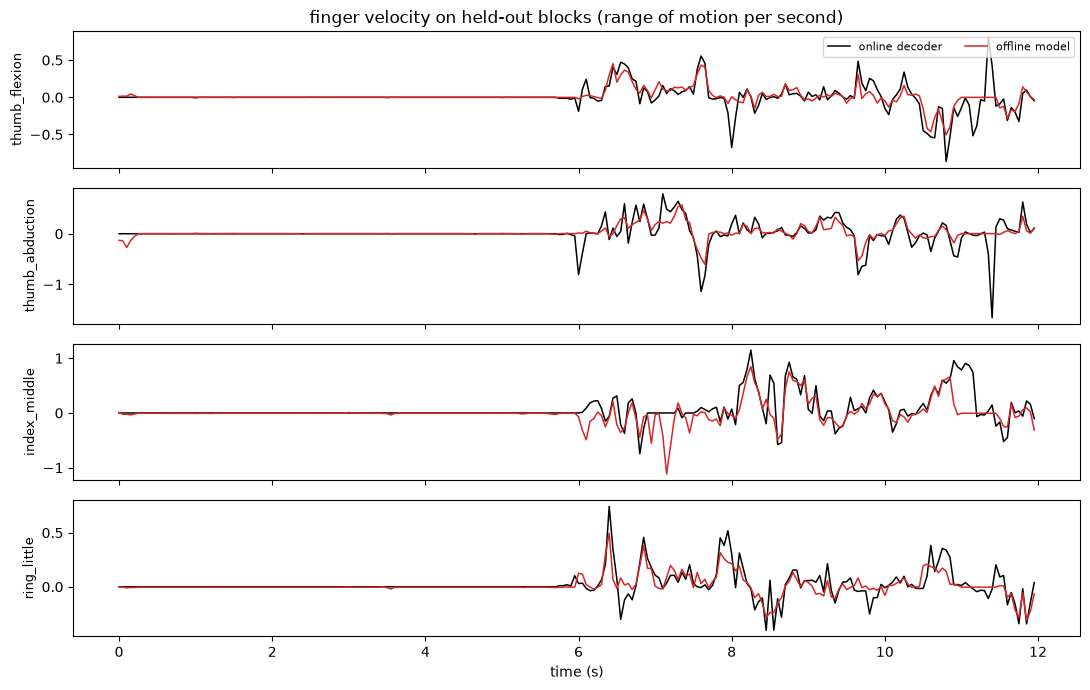

In [10]:
x_val, y_val, _ = prepare(val_idx, velocity)
velocity_model.eval()
with torch.no_grad():
    pred = (velocity_model(x_val) * v_scale).numpy()
true = (y_val * v_scale).numpy()

# One contiguous stretch of validation windows, stitched end to end.
n_win = 24
step = int(STRIDE_S * FS)
pred_series = np.concatenate([pred[i, :, :step] for i in range(n_win)], axis=1)
true_series = np.concatenate([true[i, :, :step] for i in range(n_win)], axis=1)
time = np.arange(pred_series.shape[1]) / FS

fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
for k, (ax, dim) in enumerate(zip(axes, utils.DECODED_DIMS)):
    ax.plot(time, true_series[k], color="k", lw=1.1, label="online decoder")
    ax.plot(time, pred_series[k], color="C3", lw=1.1, label="offline model")
    ax.set_ylabel(dim, fontsize=9)
axes[0].legend(fontsize=8, ncol=2, loc="upper right")
axes[0].set_title("finger velocity on held-out blocks (range of motion per second)")
axes[-1].set_xlabel("time (s)")
plt.tight_layout()

## Across days

The same frozen decoder, including its normalization statistics, applied to the other five recording days. Nothing about the task changes, only the calendar gap.

In [11]:
base_day = int(day_of[session_of == TRAIN_DAY][0])
rows = [("held out, same day", 0, *[m.mean() for m in evaluate(velocity_model, velocity, v_scale, val_idx)])]
for other in sorted(set(session_of) - {TRAIN_DAY}):
    idx = torch.tensor(np.flatnonzero(session_of == other))
    gap = int(day_of[session_of == other][0]) - base_day
    r, r2 = evaluate(velocity_model, velocity, v_scale, idx)
    rows.append((other, gap, r.mean(), r2.mean()))
rows.sort(key=lambda row: row[1])

print(f"{'day':22s} {'days apart':>10s} {'r':>8s} {'R2':>9s}")
for name, gap, r, r2 in rows:
    print(f"{name:22s} {gap:10d} {r:8.3f} {r2:+9.3f}")

day                    days apart        r        R2
t5.2023.03.09                 -14    0.411    -0.836
t5.2023.03.14                  -9    0.379    -1.423
t5.2023.03.16                  -7    0.425    -4.383
held out, same day              0    0.845    +0.708
t5.2023.04.06                  14    0.439    -1.510
t5.2023.04.13                  21    0.041    -2.986


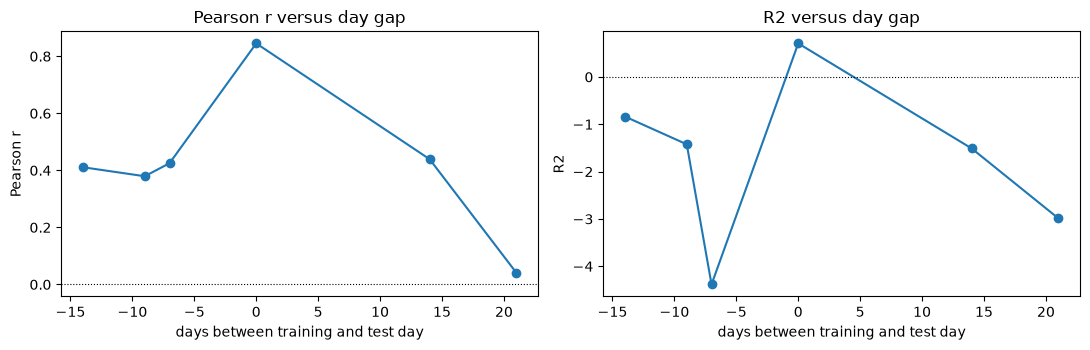

In [12]:
gaps = np.array([row[1] for row in rows])
rs = np.array([row[2] for row in rows])
r2s = np.array([row[3] for row in rows])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, values, label in zip(axes, [rs, r2s], ["Pearson r", "R2"]):
    ax.plot(gaps, values, "o-", ms=6)
    ax.axhline(0, color="k", lw=0.8, ls=":")
    ax.set(xlabel="days between training and test day", ylabel=label, title=f"{label} versus day gap")
plt.tight_layout()

## Honest reading, and what was left on the table

Within the day the fit is good and the model overfits: about 0.97 correlation on the training blocks against 0.85 on held-out blocks of the same day, with validation loss flat after roughly fifteen epochs on 2,870 windows. Across days it falls apart in the familiar order, `r` dropping to around 0.4 while `R2` goes well negative, meaning the outputs still carry some directional information but their scale and offset have drifted far enough to be worse than predicting the mean. The `willsey_2025` release spans only five weeks, so this is the early part of the curve `wilson_2025` traces over five years.

Levers deliberately not pulled, each of which would lift the numbers:

- **No smoothing.** The reference analyses apply a causal filter to the features before regressing. That alone lifts within-day performance.
- **One training day.** Pooling the other five days, or simply the other twenty-two two-degree-of-freedom blocks, roughly triples the training set.
- **No recalibration.** Refitting only the per-channel mean and standard deviation on each test day is the cheapest fix for the negative `R2` values, and is the baseline `wilson_2025` benchmarks against.
- **No causal constraint.** The convolutions here are centred, so each prediction sees 350 ms of future. The online decoder used three past bins only. This inflates the within-day numbers relative to anything deployable.
- **Position was not integrated.** Reconstructing posture by integrating predicted velocity, as the online system does, is the comparison that would connect these numbers back to target-acquisition performance.